In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("bd_city_population.csv")
df.head()

,Name,Abbr.,Division,Established,Native,Area (km2),Population_1991,Population_2001,Population_2011,Population_2022
0,Barguna,BRG,Barisal,1984,বরগুনা জেলা,1831,805000,887376,927889,1035596
1,Barishal,BRS,Barisal,1797,বরিশাল জেলা,2785,2299000,2465249,2414729,2634203
2,Bhola,BHO,Barisal,1984,ভোলা জেলা,3403,1532000,1781043,1846351,1980452
3,Jhalokati,JHA,Barisal,1984,ঝালকাঠি জেলা,707,694000,726182,709914,677559
4,Patuakhali,PAT,Barisal,1969,পটুয়াখালী জেলা,3221,1323000,1527628,1596223,1770096


In [3]:
df.drop(columns="Native", inplace=True)
df.head()

,Name,Abbr.,Division,Established,Area (km2),Population_1991,Population_2001,Population_2011,Population_2022
0,Barguna,BRG,Barisal,1984,1831,805000,887376,927889,1035596
1,Barishal,BRS,Barisal,1797,2785,2299000,2465249,2414729,2634203
2,Bhola,BHO,Barisal,1984,3403,1532000,1781043,1846351,1980452
3,Jhalokati,JHA,Barisal,1984,707,694000,726182,709914,677559
4,Patuakhali,PAT,Barisal,1969,3221,1323000,1527628,1596223,1770096


[Text(0, 0, '13'),
 Text(0, 0, '11'),
 Text(0, 0, '10'),
 Text(0, 0, '8'),
 Text(0, 0, '8'),
 Text(0, 0, '6'),
 Text(0, 0, '4'),
 Text(0, 0, '4')]

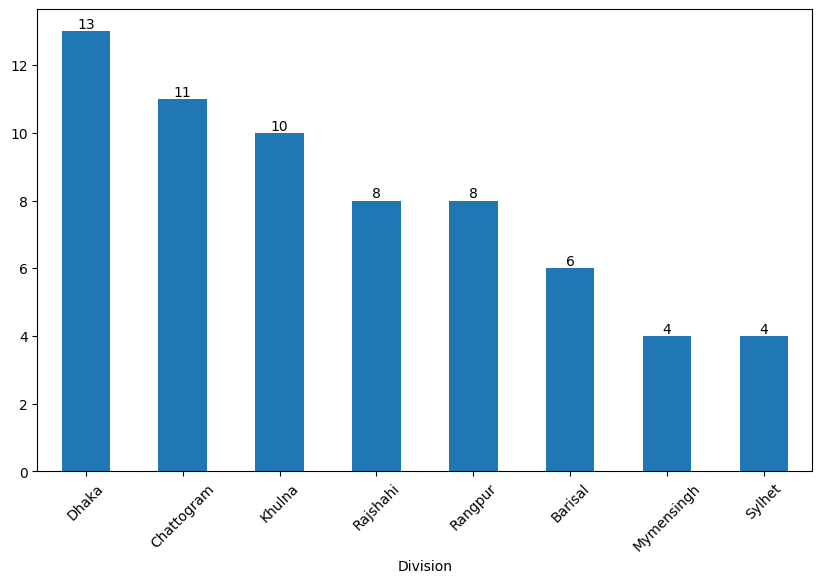

In [11]:
df["Division"].value_counts().plot(kind='bar', figsize=(10, 6))
plt.xticks(rotation=45)
ax = plt.gca()
ax.bar_label(ax.containers[0], rotation=0)

In [5]:
population_years = pd.pivot_table(data=df, index="Division", values=["Population_1991", "Population_2001", "Population_2011", "Population_2022"], aggfunc="sum")
population_years

,Population_1991,Population_2001,Population_2011,Population_2022
Division,,,,
Barisal,7757000,8549026,8652321,9325821
Chattogram,21865000,25505197,29553855,34178611
Dhaka,24931000,30806667,37893924,45644586
Khulna,13243000,15418650,16309307,17813219
Mymensingh,9010000,10321282,11427765,12637472
Rajshahi,14917000,17129332,19225903,20794019
Rangpur,12583000,14484503,16412281,18020072
Sylhet,7150000,8307941,10296996,11415113


<Axes: xlabel='Division'>

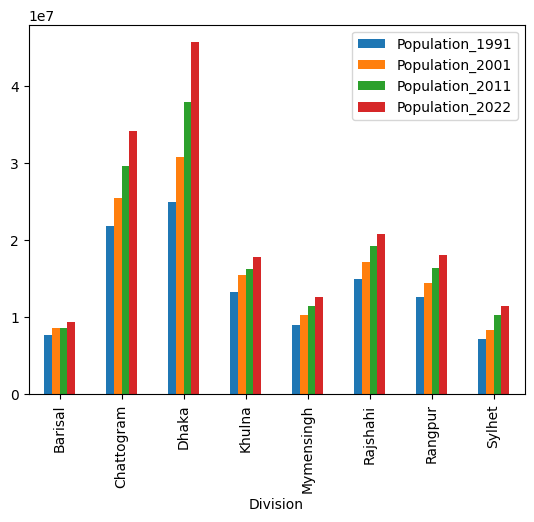

In [6]:
population_years.plot(kind="bar")

(array([0, 1, 2, 3, 4, 5, 6, 7]),
 [Text(0, 0, 'Barisal'),
  Text(1, 0, 'Chattogram'),
  Text(2, 0, 'Dhaka'),
  Text(3, 0, 'Khulna'),
  Text(4, 0, 'Mymensingh'),
  Text(5, 0, 'Rajshahi'),
  Text(6, 0, 'Rangpur'),
  Text(7, 0, 'Sylhet')])

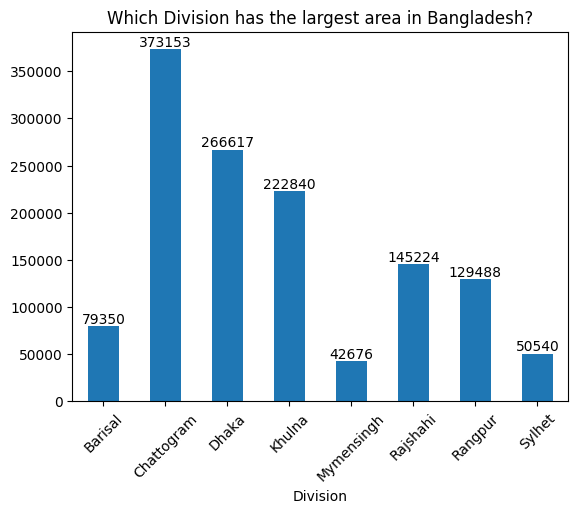

In [24]:
df["Area_km2_division"] = df.groupby("Division")["Area (km2)"].transform("sum")

df_largest_division = df.groupby("Division")["Area_km2_division"].sum()
df_largest_division.plot(kind="bar")
ax = plt.gca()
ax.bar_label(ax.containers[0], rotation=0)
plt.title("Which Division has the largest area in Bangladesh?")
plt.xticks(rotation=45)

In [30]:
area = df["Area_km2_division"].unique()
population_1991 = df.groupby("Division")["Population_1991"].sum()
population_2001 = df.groupby("Division")["Population_2001"].sum()
population_2011 = df.groupby("Division")["Population_2011"].sum()
population_2022 = df.groupby("Division")["Population_2022"].sum()

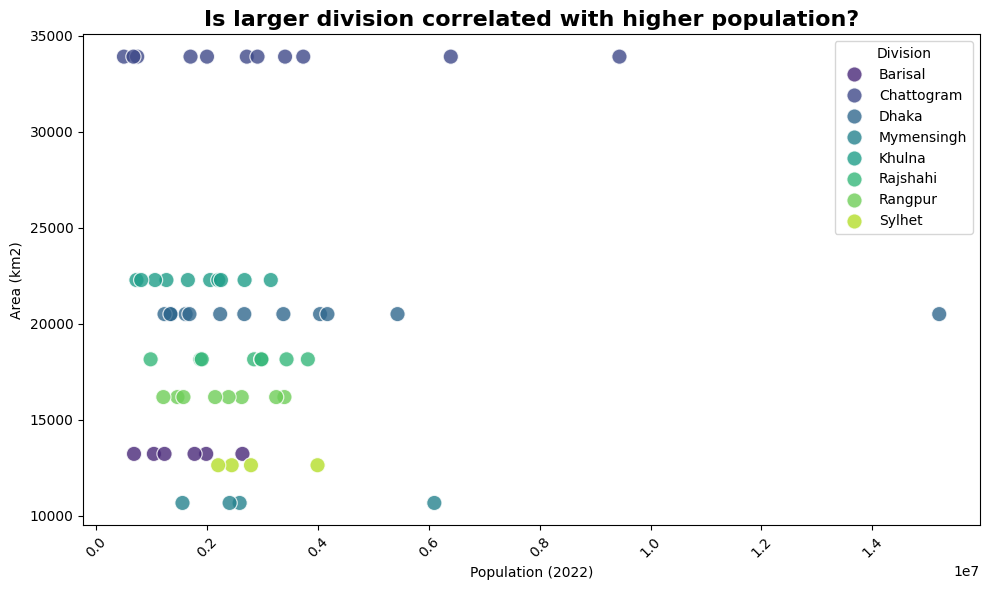

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="Population_2022", y="Area_km2_division",
                hue="Division", palette="viridis",
                s=120, alpha=0.8)

plt.title("Is larger division correlated with higher population?", fontsize=16, fontweight="bold")
plt.xlabel("Population (2022)")
plt.ylabel("Area (km2)")
plt.xticks(rotation=45)
plt.legend(title="Division")
plt.tight_layout()
plt.savefig("plot.png", dpi=300, bbox_inches="tight")
plt.show()

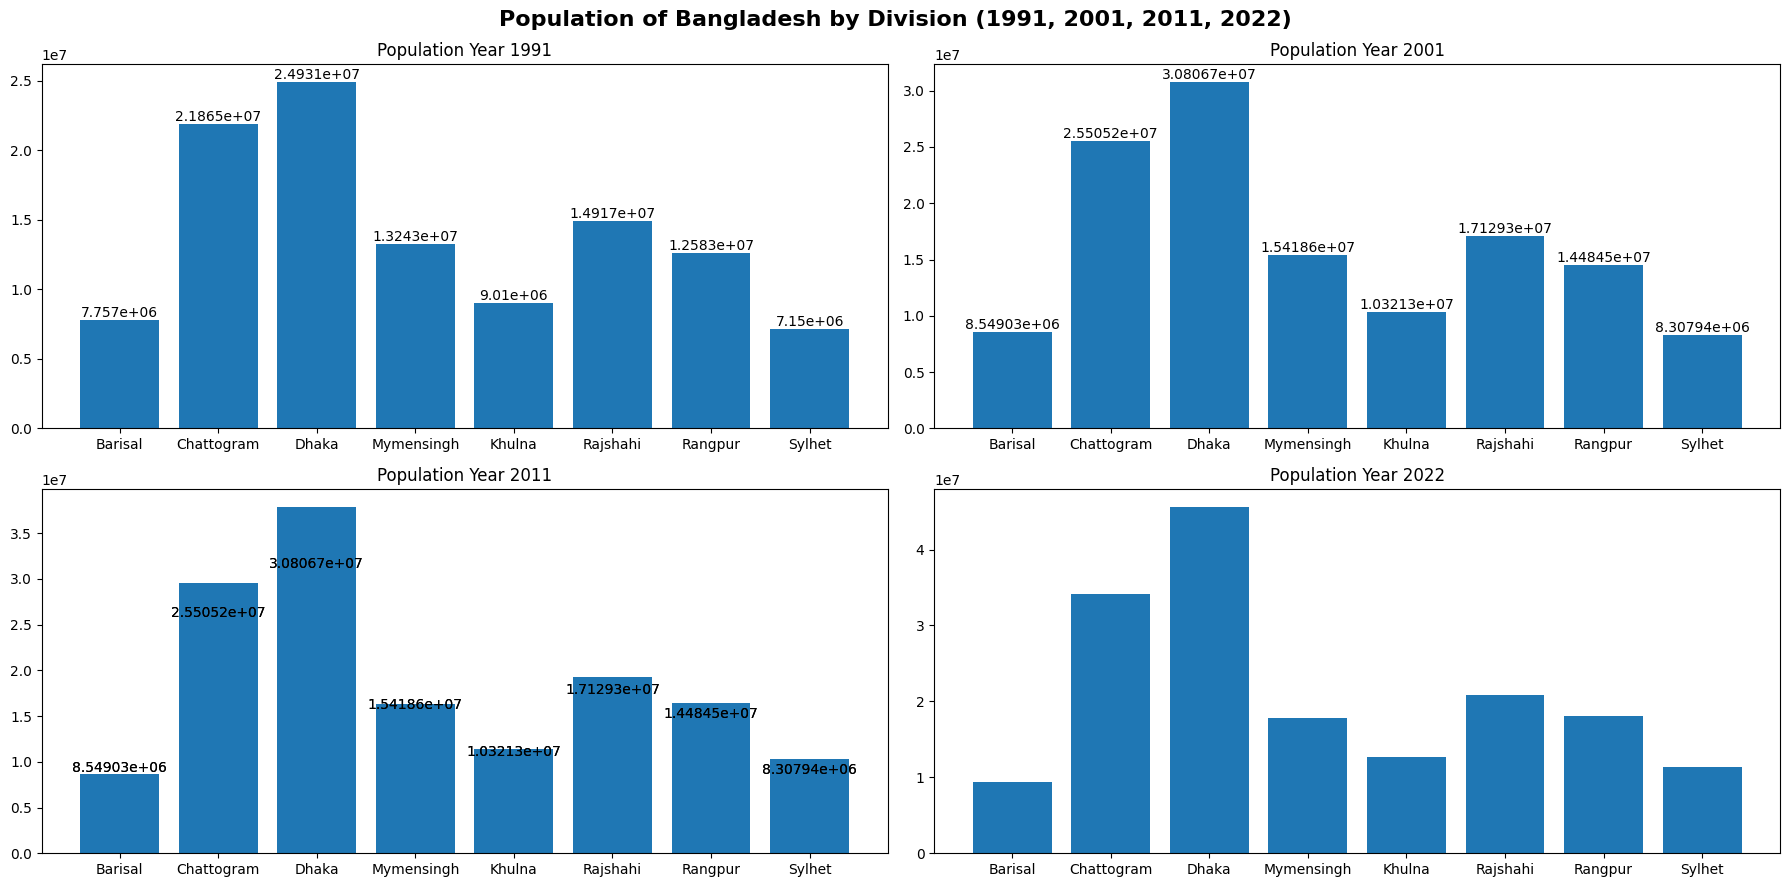

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(18, 9))
axes = axes.flatten()




axes[0].bar(df["Division"].unique(), population_1991)
axes[0].set_title("Population Year 1991")
plt.suptitle("Population of Bangladesh by Division (1991, 2001, 2011, 2022)", fontsize=16, fontweight="bold")
ax = plt.gca()
if axes[0].containers:
    axes[0].bar_label(axes[0].containers[0], rotation=0)



axes[1].bar(df["Division"].unique(), population_2001)
axes[1].set_title("Population Year 2001")
ax = plt.gca()
if axes[1].containers:
    axes[1].bar_label(axes[1].containers[0], rotation=0)

axes[2].bar(df["Division"].unique(), population_2011)
axes[2].set_title("Population Year 2011")
ax = plt.gca()
if axes[2].containers:
    axes[2].bar_label(axes[1].containers[0], rotation=0)

axes[3].bar(df["Division"].unique(), population_2022)
axes[3].set_title("Population Year 2022")
ax = plt.gca()
if axes[2].containers:
    axes[2].bar_label(axes[1].containers[0], rotation=0)

plt.tight_layout()
plt.show()

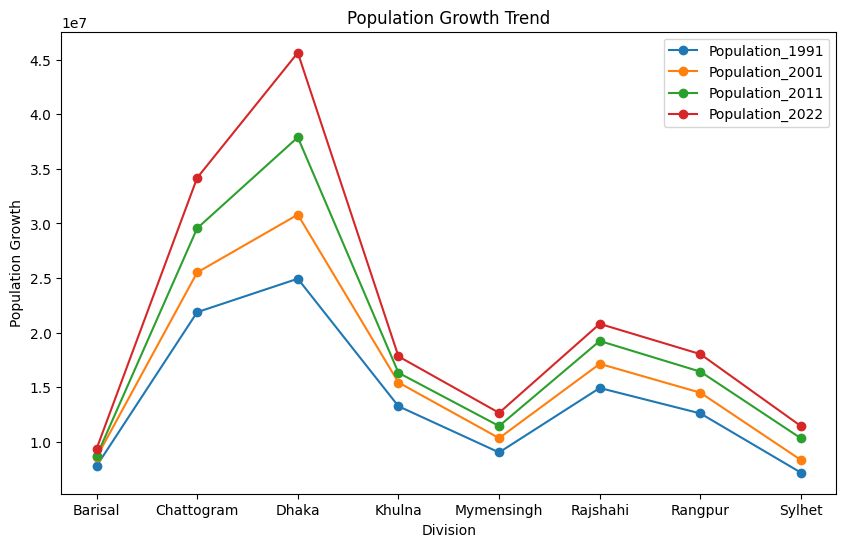

In [69]:
population_x_division = pd.pivot_table(data=df, index="Division", values=["Population_1991", "Population_2001", "Population_2011", "Population_2022"], aggfunc="sum")

population_x_division.plot(kind="line", figsize=(10, 6), marker="o")
plt.title("Population Growth Trend")
plt.xlabel("Division")
plt.ylabel("Population Growth")
plt.legend()
plt.show()